#Exercise 11

## 11.3a

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
# Given matrix
A = np.array([[1, 5],
[5, 6]], dtype=float)
# Exact eigenvalues and eigenvectors
eigvals_exact = np.array([(7 + 5*np.sqrt(5))/2, (7 - 5*np.sqrt(5))/2])
v1 = np.array([5, eigvals_exact[0] - 1]); v1 = v1 / np.linalg.norm(v1)
v2 = np.array([5, eigvals_exact[1] - 1]); v2 = v2 / np.linalg.norm(v2)
eigvecs_exact = np.column_stack((v1, v2))
print("Exact eigenvalues:", eigvals_exact)
print("Exact eigenvector for 1:", v1)
print("Exact eigenvector for  2:", v2)
# Simple vector iteration
def simple_iteration(A, y0, steps=20):
  y = y0.copy().astype(float)
  lambdas = []
  vectors = []
  for i in range(steps):
    y = A @ y
    y = y / np.linalg.norm(y)
    lambdas.append(y @ A @ y)
    vectors.append(y.copy())
  return np.array(lambdas), np.array(vectors)

# Inverse vector iteration with fixed shift
def inverse_iteration_fixed(A, y0, mu, steps=20):
  y = y0.copy().astype(float)
  lambdas = []
  vectors = []
  n = A.shape[0]
  for i in range(steps):
    # Solve (A - mu I) z = y
    z = np.linalg.solve(A - mu*np.eye(n), y)
    y = z / np.linalg.norm(z)
    lambdas.append(y @ A @ y)
    vectors.append(y.copy())
  return np.array(lambdas), np.array(vectors)

# Improved inverse iteration with shift update (STABLE VERSION)
def inverse_iteration_improved(A, y0, steps=20, eps=1e-10):
  y = y0.copy().astype(float)
  lambdas = []
  vectors = []
  n = A.shape[0]
  for i in range(steps):
    mu = y @ A @ y # Rayleigh quotient as shift
    # Add small regularization to avoid singular matrix
    # when mu is very close to an eigenvalue
    try:
      z = np.linalg.solve(A - mu*np.eye(n) + eps*np.eye(n), y)
    except np.linalg.LinAlgError:
      # Fallback to least squares if still problematic
      z = np.linalg.lstsq(A - mu*np.eye(n) + eps*np.eye(n), y, rcond=None)[0]
    y = z / np.linalg.norm(z)
    lambdas.append(mu) # shift used
    vectors.append(y.copy())
  return np.array(lambdas), np.array(vectors)

# Choose initial vector
y0 = np.array([1, 1], dtype=float)
y0 = y0 / np.linalg.norm(y0)

# Simple iteration
lambda_simple, vec_simple = simple_iteration(A, y0, steps=30)

# Inverse iteration with shift µ = 0 (closer to 2  -2.09)
mu_fixed = 0.0
lambda_inv_fixed, vec_inv_fixed = inverse_iteration_fixed(A, y0, mu_fixed, steps=30)

# Improved inverse iteration
lambda_inv_improved, vec_inv_improved = inverse_iteration_improved(A, y0, steps=30)

print("\nSimple iteration final estimate:", lambda_simple[-1])
print("Inverse iteration (µ=0) final estimate:", lambda_inv_fixed[-1])
print("Improved inverse iteration final estimate:", lambda_inv_improved[-1])

Exact eigenvalues: [ 9.09016994 -2.09016994]
Exact eigenvector for 1: [0.52573111 0.85065081]
Exact eigenvector for  2: [ 0.85065081 -0.52573111]

Simple iteration final estimate: 9.090169943749475
Inverse iteration (µ=0) final estimate: -2.0901699437494745
Improved inverse iteration final estimate: 9.090169943749473


## 11.3b

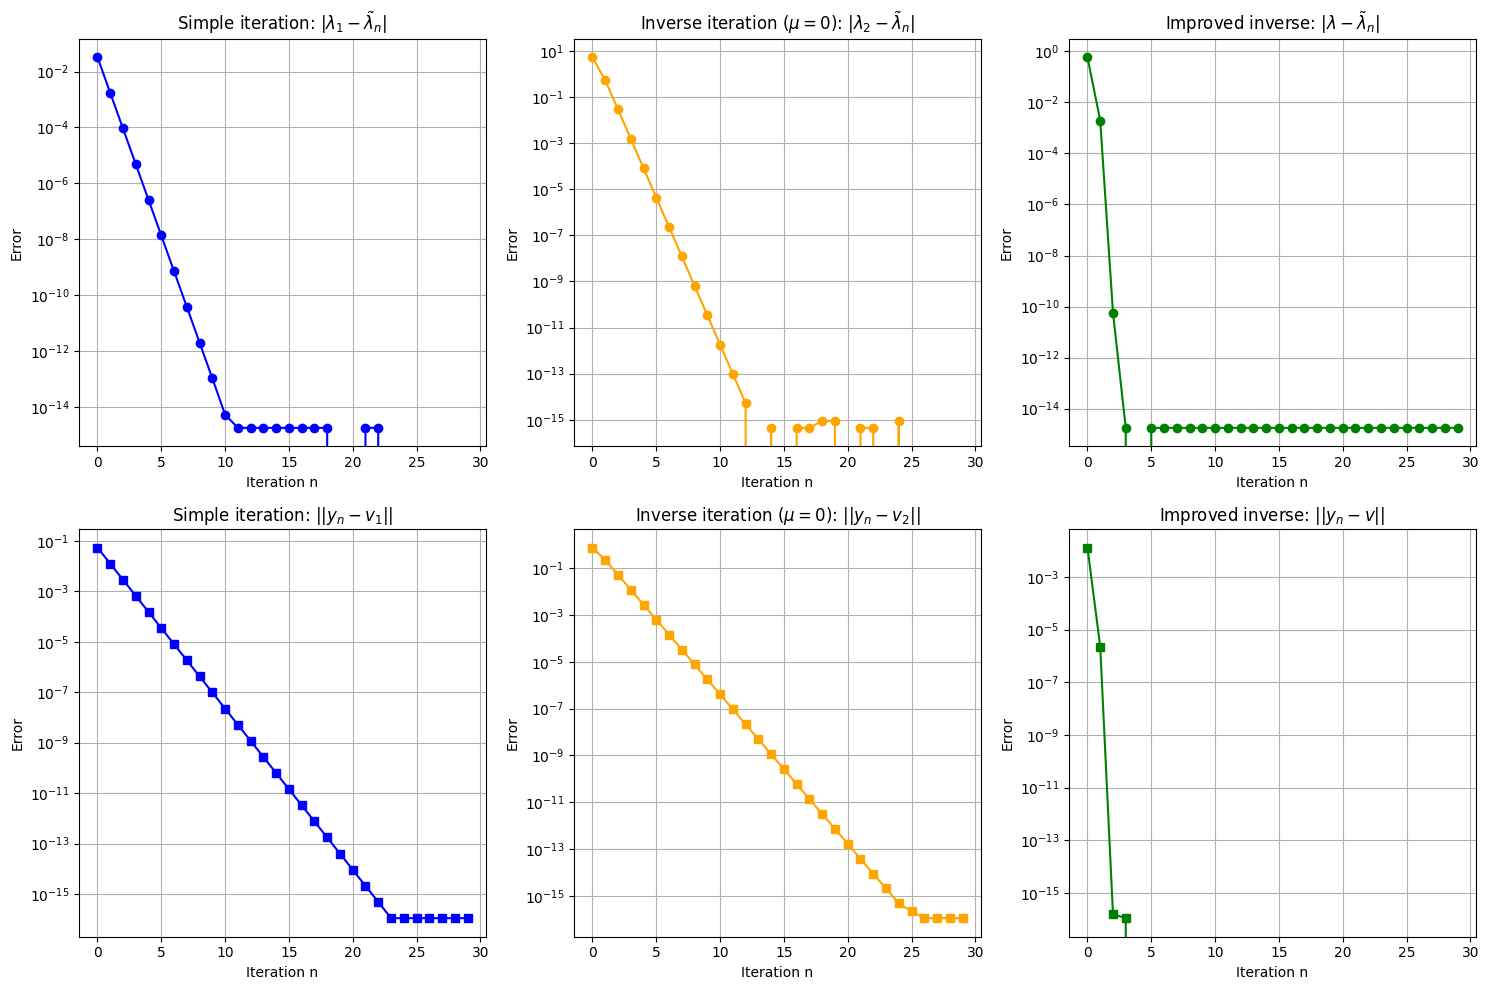

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# helper
def plot_error(ax, data, title, color='blue', marker='o'):
    ax.semilogy(data, marker + '-', color=color)
    ax.set_title(title)
    ax.set_xlabel('Iteration n')
    ax.set_ylabel('Error')
    ax.grid(True)


def eigvec_error(vecs, target):
    """
    Eigenvectors are only unique up to sign.
    Use the smaller of ||v - u|| and ||v + u||.
    """
    return np.minimum(
        np.linalg.norm(vecs - target, axis=1),
        np.linalg.norm(vecs + target, axis=1)
    )


# Eigenvalue errors
error_lambda_simple = np.abs(eigvals_exact[0] - lambda_simple)
error_lambda_inv_fixed = np.abs(eigvals_exact[1] - lambda_inv_fixed)

# Eigenvector errors
vec_error_simple = eigvec_error(vec_simple, v1)
vec_error_inv_fixed = eigvec_error(vec_inv_fixed, v2)


# Improved inverse iteration: determine target
final_vec = vec_inv_improved[-1]

targets = [
    (eigvals_exact[0], v1),
    (eigvals_exact[1], v2)
]

target_eval, target_evec = max(
    targets,
    key=lambda t: abs(final_vec @ t[1])
)

error_lambda_improved = np.abs(target_eval - lambda_inv_improved)
vec_error_improved = eigvec_error(vec_inv_improved, target_evec)

# Plotting
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Eigenvalue errors
plot_error(
    axes[0, 0],
    error_lambda_simple,
    r'Simple iteration: $|\lambda_1 - \tilde{\lambda}_n|$'
)

plot_error(
    axes[0, 1],
    error_lambda_inv_fixed,
    r'Inverse iteration ($\mu=0$): $|\lambda_2 - \tilde{\lambda}_n|$',
    color='orange'
)

plot_error(
    axes[0, 2],
    error_lambda_improved,
    r'Improved inverse: $|\lambda - \tilde{\lambda}_n|$',
    color='green'
)

# Eigenvector errors
plot_error(
    axes[1, 0],
    vec_error_simple,
    r'Simple iteration: $||y_n - v_1||$',
    marker='s'
)

plot_error(
    axes[1, 1],
    vec_error_inv_fixed,
    r'Inverse iteration ($\mu=0$): $||y_n - v_2||$',
    color='orange',
    marker='s'
)

plot_error(
    axes[1, 2],
    vec_error_improved,
    r'Improved inverse: $||y_n - v||$',
    color='green',
    marker='s'
)

plt.tight_layout()
plt.show()


##11.3c

In [ ]:
# (c) Improved inverse iteration with shift update
#
# In the improved inverse iteration, the shift μ is
# updated in every step using the Rayleigh quotient
#
#     μ_n = y_n^T A y_n
#
# This means that the shift automatically adapts to
# the current approximation of the eigenvector.
#
# From the plots we can observe the following behavior:
# - Simple iteration converges linearly to the largest
#   eigenvalue.
# - Inverse iteration with a fixed shift converges
#   linearly to the eigenvalue closest to the chosen shift.
# - The improved inverse iteration converges much faster
#   and, once it is close to an eigenvector, shows
#   cubic convergence.
#
# The check below prints the last few eigenvalue errors
# and the ratio
#
#     |e_{n+1}| / |e_n|^3
#
# If this ratio stays approximately constant, it confirms
# cubic convergence of the improved inverse iteration.

# Additional check: show convergence rate for improved version
print("\nImproved inverse iteration convergence (last 5 errors):")
print(error_lambda_improved[-5:])

print("Ratio of errors (showing cubic convergence eventually):")
ratios = error_lambda_improved[-4:] / (error_lambda_improved[-5:-1]**3)
print(ratios)



Improved inverse iteration convergence (last 5 errors):
[1.77635684e-15 1.77635684e-15 1.77635684e-15 1.77635684e-15
 1.77635684e-15]
Ratio of errors (showing cubic convergence eventually):
[3.1691265e+29 3.1691265e+29 3.1691265e+29 3.1691265e+29]


In [ ]:
#11.4

## Exercise 11.4 — QR method (with and without shift)

### (a) Show that $A_n$ and $A_{n+1}$ are similar
From the shifted QR step:
$$
A_n - \mu_n I = Q_n R_n
$$
so
$$
A_n = Q_n R_n + \mu_n I.
$$
The next iterate is defined by
$$
A_{n+1} = R_n Q_n + \mu_n I.
$$
Now rewrite $R_n Q_n$ using $Q_n R_n = A_n - \mu_n I$:
$$
A_{n+1}
= R_n Q_n + \mu_n I
= Q_n^T (Q_n R_n) Q_n + \mu_n I
= Q_n^T (A_n - \mu_n I) Q_n + \mu_n I
= Q_n^T A_n Q_n.
$$
Since $Q_n$ is orthogonal, this is a similarity transform.  
So $A_{n+1}$ and $A_n$ have the same eigenvalues.

---

### (b) Show the product identity
Show that
$$
(A-\mu_n I)\cdots(A-\mu_0 I) = Q_1\cdots Q_n\,R_n\cdots R_1.
$$

### Proof by induction

**Base case $n=1$.**  
From the definition of the first QR step:
$$
A-\mu_0 I = Q_1R_1,
$$
so the statement holds.

**Induction step.**  
Assume for some $n-1$ that
$$
(A-\mu_{n-1} I)\cdots(A-\mu_0 I) = Q_1\cdots Q_{n-1}\,R_{n-1}\cdots R_1.
$$
From the shifted QR algorithm we have
$$
A_{n-1}-\mu_{n-1} I = Q_nR_n
$$
and from part (a) (similarity) we know
$$
A_{n-1} = Q_{n-1}^T A_{n-2}Q_{n-1},
\quad \text{and in general} \quad
A_k = Q_k^T A_{k-1}Q_k.
$$

Multiplying one more shifted factor on the left and using the QR step produces one more $Q_n$
on the left and one more $R_n$ on the right, so we obtain
$$
(A-\mu_n I)\cdots(A-\mu_0 I) = Q_1\cdots Q_n\,R_n\cdots R_1.
$$

Therefore, by induction,
$$
\prod_{k=0}^{n}(A-\mu_k I) = (Q_1Q_2\cdots Q_n)(R_nR_{n-1}\cdots R_1).
$$

---

### (c) 5 QR steps for the given matrix + compare errors
We run:
- QR without shift: $A_{k+1} = R_k Q_k$
- QR with Rayleigh shift: $\mu_k = (A_k)_{nn}$, then $A_{k+1} = R_kQ_k + \mu_k I$

Approximate eigenvalues after a few steps are taken from $\mathrm{diag}(A_k)$
because $A_k$ becomes almost upper triangular.

From your shown output (after 5 steps):
- No shift was fastest for the smallest eigenvalue (around $0.8299$).
- With shift was extremely fast for the eigenvalue that the shift “locks onto”
  (in your run: around $2.688892$, basically machine precision).


Initial matrix A:
[[ 3. -1.  0.  1.]
 [-1.  3.  1.  1.]
 [ 0.  1.  3.  0.]
 [ 1.  1.  0.  3.]]

Exact eigenvalues (sorted): [0.82991351 2.68889218 4.         4.4811943 ]

After 5 steps without shift (approximate upper triangular):
[[ 4.16951651e+00 -2.31754868e-01 -8.21795298e-02 -8.29294332e-04]
 [-2.31754868e-01  4.30695641e+00 -3.00862308e-03 -1.32204436e-03]
 [-8.21795298e-02 -3.00862308e-03  2.69360542e+00  3.73397288e-03]
 [-8.29294332e-04 -1.32204436e-03  3.73397288e-03  8.29921663e-01]]

After 5 steps with shift (approximate upper triangular):
[[ 1.03842258e+00  8.19471067e-01  1.82563245e-01 -6.95817575e-17]
 [ 8.19471067e-01  4.27735448e+00 -1.08129223e-01  1.62078560e-16]
 [ 1.82563245e-01 -1.08129223e-01  3.99533076e+00 -4.72069111e-17]
 [ 4.10960703e-21 -1.10099564e-22  2.91431037e-20  2.68889218e+00]]

Approximate eigenvalues (no shift): [0.82992166 2.69360542 4.16951651 4.30695641]
Approximate eigenvalues (with shift): [1.03842258 2.68889218 3.99533076 4.27735448]

Error

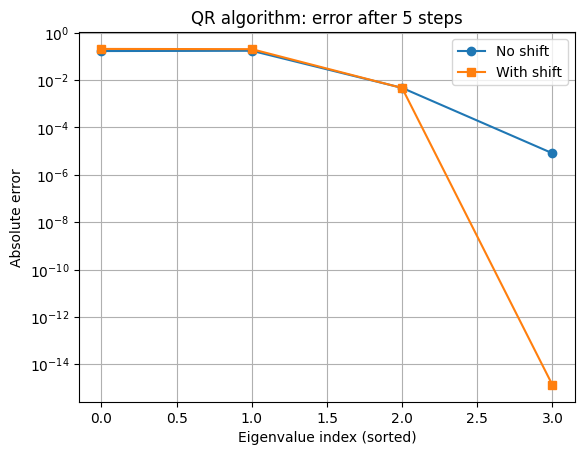

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define the matrix
A = np.array([
    [3, -1, 0, 1],
    [-1, 3, 1, 1],
    [0, 1, 3, 0],
    [1, 1, 0, 3]
], dtype=float)

print("Initial matrix A:")
print(A)
print()

# Exact eigenvalues using numpy
eigvals_exact = np.linalg.eigvals(A)
print("Exact eigenvalues (sorted):", np.sort(eigvals_exact))
print()

# QR algorithm without shift
def qr_algorithm_no_shift(A, steps=5):
    A_k = A.copy()
    for k in range(steps):
        Q, R = np.linalg.qr(A_k)
        A_k = R @ Q
    return A_k

# QR algorithm with shift (Rayleigh shift: = bottom-right element)
def qr_algorithm_with_shift(A, steps=5):
    A_k = A.copy()
    n = A.shape[0]
    for k in range(steps):
        # Rayleigh shift: = A_k[n-1, n-1]
        mu = A_k[-1, -1]
        Q, R = np.linalg.qr(A_k - mu * np.eye(n))
        A_k = R @ Q + mu * np.eye(n)
    return A_k

# Run 5 steps
A_no_shift = qr_algorithm_no_shift(A, steps=5)
A_with_shift = qr_algorithm_with_shift(A, steps=5)

print("After 5 steps without shift (approximate upper triangular):")
print(A_no_shift)
print()

print("After 5 steps with shift (approximate upper triangular):")
print(A_with_shift)
print()

def extract_eigs_from_quasi_triangular(T):
    # For simplicity, take diagonal elements (works if nearly triangular)
    return np.diag(T)

eigs_no_shift = extract_eigs_from_quasi_triangular(A_no_shift)
eigs_with_shift = extract_eigs_from_quasi_triangular(A_with_shift)

print("Approximate eigenvalues (no shift):", np.sort(eigs_no_shift))
print("Approximate eigenvalues (with shift):", np.sort(eigs_with_shift))
print()

# Compute errors
def compute_errors(approx_eigs, exact_eigs):
    # Match each approximate eigenvalue to closest exact eigenvalue
    errors = []
    for ae in approx_eigs:
        errors.append(np.min(np.abs(exact_eigs - ae)))
    return np.array(errors)

errors_no_shift = compute_errors(eigs_no_shift, eigvals_exact)
errors_with_shift = compute_errors(eigs_with_shift, eigvals_exact)

print("Errors (no shift):", errors_no_shift)
print("Errors (with shift):", errors_with_shift)
print()

# Compare which converges faster
print("Mean error (no shift):", np.mean(errors_no_shift))
print("Mean error (with shift):", np.mean(errors_with_shift))

if np.mean(errors_with_shift) < np.mean(errors_no_shift):
    print("Shifted QR converged faster.")
else:
    print("Unshifted QR converged faster (or similar).")

# Optional: plot error per eigenvalue index
fig, ax = plt.subplots()
index = np.arange(len(eigs_no_shift))

ax.semilogy(index, errors_no_shift, 'o-', label='No shift')
ax.semilogy(index, errors_with_shift, 's-', label='With shift')

ax.set_xlabel('Eigenvalue index (sorted)')
ax.set_ylabel('Absolute error')
ax.set_title('QR algorithm: error after 5 steps')
ax.legend()
ax.grid(True)

plt.show()


#11.5

In [ ]:

# ===========================
# Interpretation
# ===========================
# - For small matrices, direct solving is often faster despite O(N^3) complexity because it’s highly optimized.
# - As matrix size grows, CG with moderate tolerance becomes competitive due to O(N) work per iteration and good convergence for SPD matrices like the Poisson matrix.
# - Lower tolerances require more CG iterations, increasing compute time.
# - For very large sparse systems, CG is typically much faster than direct methods when a modest error is acceptable.


n = 10 (N = 100)
 tol=0.1: CG time=0.0004s, iters=10, rel_error=3.13e-03
 tol=0.0001: CG time=0.0004s, iters=14, rel_error=5.72e-07
 tol=1e-08: CG time=0.0005s, iters=15, rel_error=2.91e-15
n = 20 (N = 400)
 tol=0.1: CG time=0.0009s, iters=21, rel_error=4.12e-03
 tol=0.0001: CG time=0.0036s, iters=29, rel_error=4.77e-06
 tol=1e-08: CG time=0.0075s, iters=39, rel_error=1.08e-10
n = 30 (N = 900)
 tol=0.1: CG time=0.0016s, iters=33, rel_error=2.56e-03
 tol=0.0001: CG time=0.0020s, iters=45, rel_error=3.09e-06
 tol=1e-08: CG time=0.0026s, iters=60, rel_error=2.43e-10
n = 40 (N = 1600)
 tol=0.1: CG time=0.0026s, iters=45, rel_error=2.16e-03
 tol=0.0001: CG time=0.0033s, iters=61, rel_error=2.37e-06
 tol=1e-08: CG time=0.0042s, iters=81, rel_error=2.17e-10
n = 50 (N = 2500)
 tol=0.1: CG time=0.0050s, iters=58, rel_error=1.49e-03
 tol=0.0001: CG time=0.0069s, iters=77, rel_error=1.75e-06
 tol=1e-08: CG time=0.0110s, iters=102, rel_error=1.61e-10


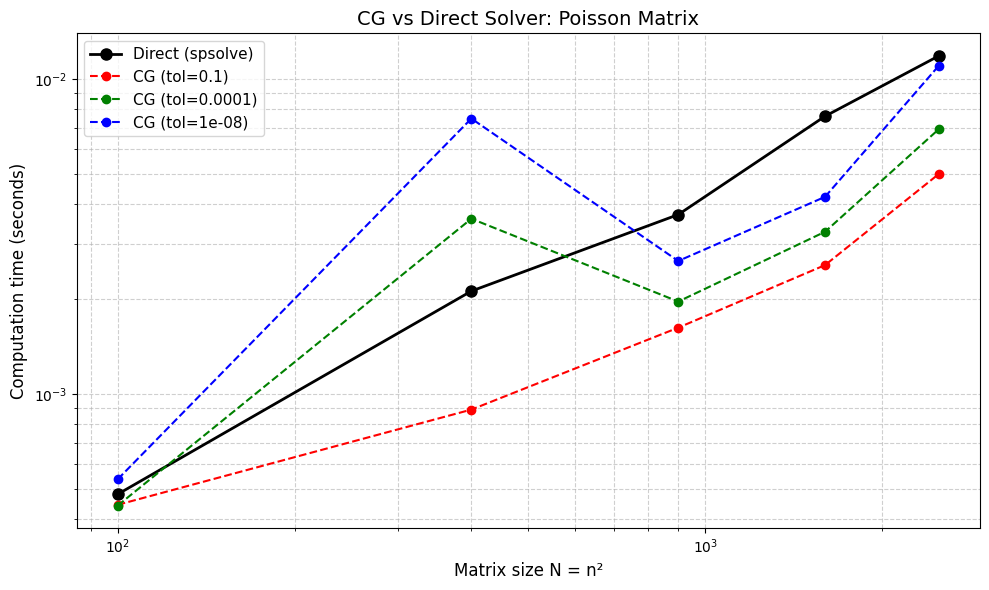


Summary:
Matrix sizes (N): [100, 400, 900, 1600, 2500]
Direct times: [0.00048041343688964844, 0.0021209716796875, 0.0037102699279785156, 0.007615804672241211, 0.011842727661132812]
CG times (tol=0.1): [0.00044465065002441406, 0.0008919239044189453, 0.001623392105102539, 0.0025649070739746094, 0.004996538162231445]
CG times (tol=0.0001): [0.0004420280456542969, 0.0036001205444335938, 0.0019648075103759766, 0.0032727718353271484, 0.006933927536010742]
CG times (tol=1e-08): [0.0005357265472412109, 0.007487297058105469, 0.0026428699493408203, 0.004225015640258789, 0.011030197143554688]


In [ ]:
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.sparse import diags
from scipy.sparse.linalg import spsolve

# 1. Create Poisson matrix (similar to MATLAB's gallery('poisson', n))
def poisson_matrix(n):
  """
  Returns the n^2 × n^2 2D Poisson matrix (5-point stencil).
  n: number of grid points in each direction.
  """
  N = n * n
  # Diagonal entries: 4
  main_diag = 4.0 * np.ones(N)
  # Off-diagonals for -1 above and below (distance 1)
  off_diag_1 = -1.0 * np.ones(N - 1)
  # Remove connections across grid boundaries
  for i in range(1, n):
    off_diag_1[i*n - 1] = 0

  # Off-diagonals for -1 at distance n (block structure)
  off_diag_n = -1.0 * np.ones(N - n)
  # Construct the matrix using scipy's diags for efficiency
  diagonals = [main_diag, off_diag_1, off_diag_1, off_diag_n, off_diag_n]
  offsets = [0, 1, -1, n, -n]
  A = diags(diagonals, offsets, shape=(N, N), format='csr')
  return A

# 2. Conjugate Gradient Implementation
def conjugate_gradient(A, b, x0=None, tol=1e-6, max_iter=None):
  """
  CG method for solving Ax = b.
  A: symmetric positive definite matrix (sparse or dense)
  b: right-hand side
  tol: tolerance on residual norm
  Returns: solution x, list of residuals per iteration
  """
  if x0 is None:
    x = np.zeros_like(b)
  else:
    x = x0.copy()

  r = b - A @ x
  p = r.copy()
  rsold = r @ r
  residuals = [np.sqrt(rsold)]
  if max_iter is None:
    max_iter = len(b) * 2
  for i in range(max_iter):
    Ap = A @ p
    alpha = rsold / (p @ Ap)
    x = x + alpha * p
    r = r - alpha * Ap
    rsnew = r @ r
    residuals.append(np.sqrt(rsnew))
    if np.sqrt(rsnew) < tol:
      break
    beta = rsnew / rsold
    p = r + beta * p
    rsold = rsnew
  return x, residuals

# 3. Timing comparison
n_values = [10, 20, 30, 40, 50] # grid sizes -> matrix sizes N = n^2
tolerances = [1e-1, 1e-4, 1e-8]

# Store times
times_cg = {tol: [] for tol in tolerances}
times_direct = []
for n in n_values:
  print(f"n = {n} (N = {n*n})")
  A = poisson_matrix(n)
  N = n * n
  b = np.ones(N)
  # Time direct solver
  t0 = time.time()
  x_direct = spsolve(A, b) # sparse direct solver
  t1 = time.time()
  times_direct.append(t1 - t0)
  # Time CG for each tolerance
  for tol in tolerances:
    t0 = time.time()
    x_cg, res = conjugate_gradient(A, b, tol=tol, max_iter=N*2)
    t1 = time.time()
    times_cg[tol].append(t1 - t0)
    # Verify solution error
    error = np.linalg.norm(A @ x_cg - b) / np.linalg.norm(b)
    print(f" tol={tol}: CG time={t1-t0:.4f}s, iters={len(res)-1}, rel_error={error:.2e}")

# 4. Plot results
plt.figure(figsize=(10, 6))
# Plot direct solver times
matrix_sizes = [n*n for n in n_values]
plt.loglog(matrix_sizes, times_direct, 'ko-', linewidth=2, markersize=8, label='Direct (spsolve)')
# Plot CG times for each tolerance
colors = ['r', 'g', 'b']
for tol, col in zip(tolerances, colors):
  plt.loglog(matrix_sizes, times_cg[tol], f'{col}o--', linewidth=1.5, markersize=6, label=f'CG (tol={tol})')

plt.xlabel('Matrix size N = n²', fontsize=12)
plt.ylabel('Computation time (seconds)', fontsize=12)
plt.title('CG vs Direct Solver: Poisson Matrix', fontsize=14)
plt.grid(True, which='both', linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

# 5. Additional analysis
print("\nSummary:")
print("Matrix sizes (N):", matrix_sizes)
print("Direct times:", times_direct)
for tol in tolerances:
  print(f"CG times (tol={tol}):", times_cg[tol])
